In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

year
2024    15887
2025    17740
Name: events, dtype: int64


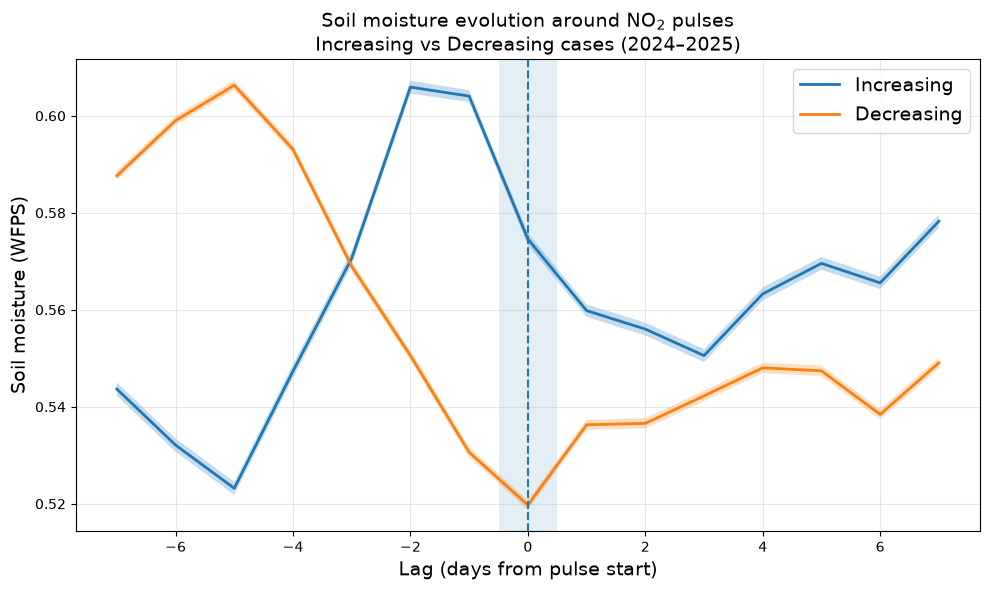

In [4]:
# 2024 + 2025 pooled
DIR = '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/'+ ("final_datasets_excl")
YEARS_WFPS = [2024, 2025]
events_long_wfps = pd.concat(
    [pd.read_parquet(f'{DIR}/lowCF_7day_events_long_MCD12Q1mask_{y}.parquet', engine='pyarrow').assign(year=y)
     for y in YEARS_WFPS], ignore_index=True)
print(events_long_wfps.groupby('year')['event_id'].nunique().rename('events'))

plot_df = events_long_wfps[events_long_wfps["sm_class"].isin(["increasing", "decreasing"])].copy()
plot_df = plot_df.dropna(subset=["lag_days", "WFPS_c", "sm_class"])

summary = (plot_df.groupby(["sm_class", "lag_days"])["WFPS_c"]
           .agg(["mean", "std", "count"]).reset_index())
summary["sem"] = summary["std"] / np.sqrt(summary["count"])

inc = summary[summary["sm_class"] == "increasing"].copy()
dec = summary[summary["sm_class"] == "decreasing"].copy()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(inc["lag_days"], inc["mean"], label="Increasing", linewidth=2)
ax.fill_between(inc["lag_days"], inc["mean"] - inc["sem"], inc["mean"] + inc["sem"], alpha=0.25)
ax.plot(dec["lag_days"], dec["mean"], label="Decreasing", linewidth=2)
ax.fill_between(dec["lag_days"], dec["mean"] - dec["sem"], dec["mean"] + dec["sem"], alpha=0.25)

ax.axvline(0, linestyle="--", linewidth=1.5)
ax.axvspan(-0.5, 0.5, alpha=0.12)
ax.set_xlabel("Lag (days from pulse start)", fontsize=14)
ax.set_ylabel("Soil moisture (WFPS)",fontsize=14)
ax.set_title(f"Soil moisture evolution around NO$_2$ pulses\nIncreasing vs Decreasing cases ({YEARS_WFPS[0]}–{YEARS_WFPS[-1]})",fontsize=14)

ax.legend(fontsize=14)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() 


2024, 10:00–17:59 local, ≥70% endmember: pulses by soil_group
sm_class           decreasing  increasing  total  % increasing
soil_group                                                    
coarse                      2           0      2           0.0
fine                      295         189    484          39.0
medium                   1134         565   1699          33.3
moderately coarse          64          31     95          32.6


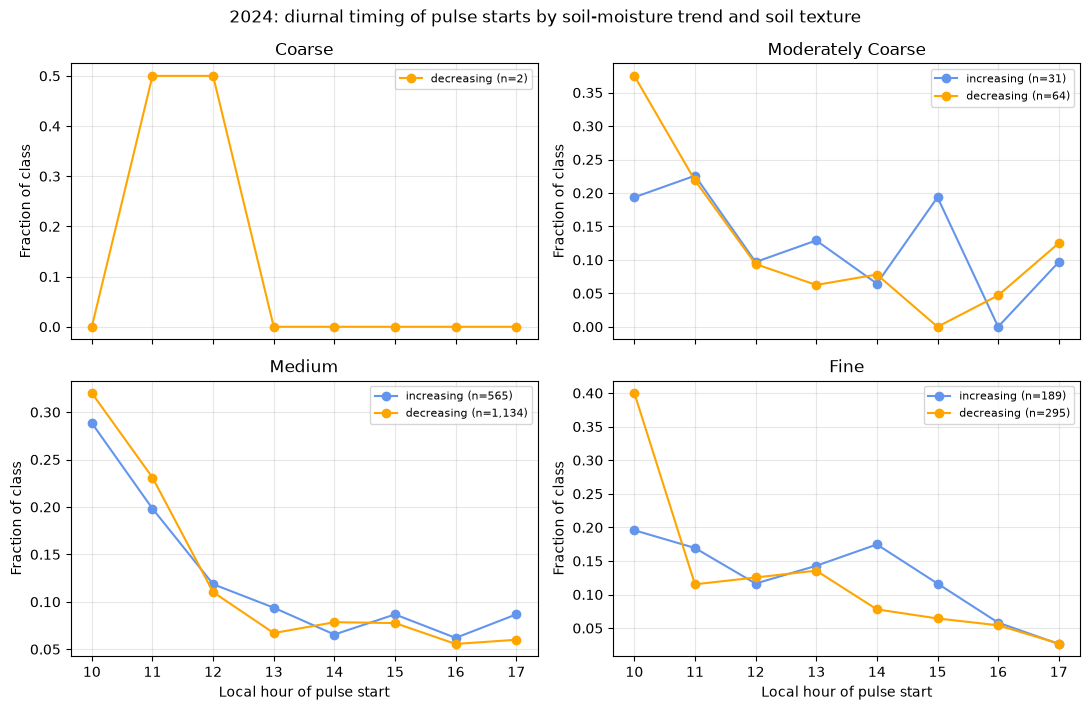


2025, 10:00–17:59 local, ≥70% endmember: pulses by soil_group
sm_class           decreasing  increasing  total  % increasing
soil_group                                                    
fine                      474         118    592          19.9
medium                    942         397   1339          29.6
moderately coarse          71          46    117          39.3


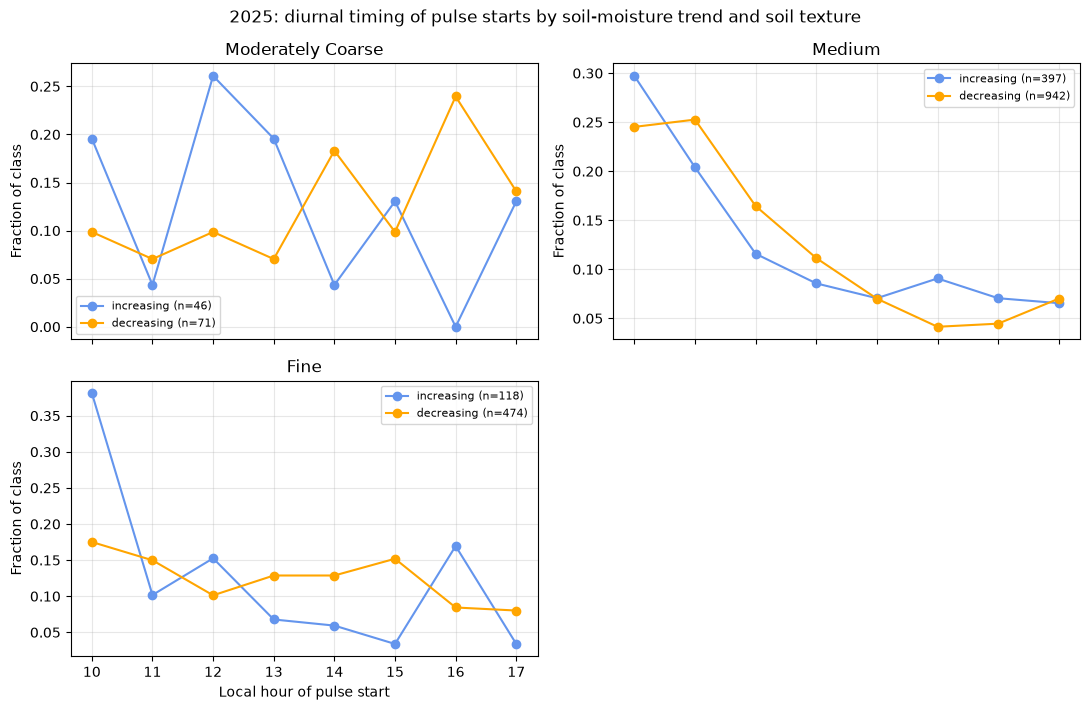


2024–2025, 10:00–17:59 local, ≥70% endmember: pulses by soil_group
sm_class           decreasing  increasing  total  % increasing
soil_group                                                    
coarse                      2           0      2           0.0
fine                      769         307   1076          28.5
medium                   2076         962   3038          31.7
moderately coarse         135          77    212          36.3


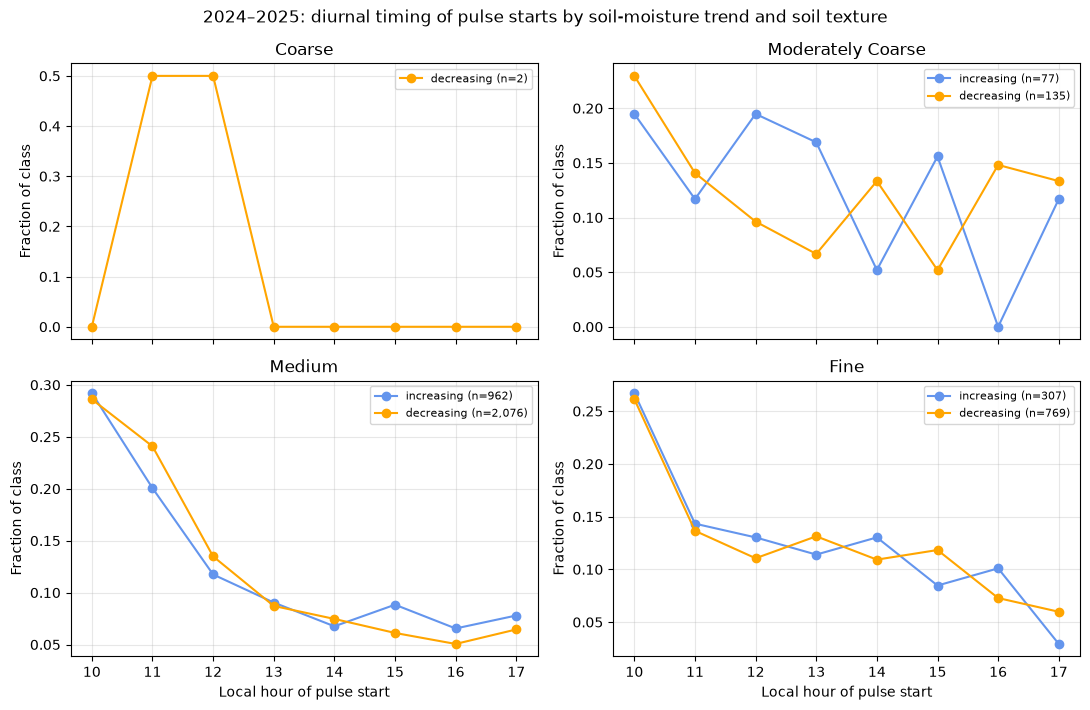

In [5]:
YEARS = [2024, 2025]
HOUR_MIN, HOUR_MAX = 10, 17            
THRESHOLD = 0.70                       
BY = "soil_group"                      
DIR = "/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/"+ ("final_datasets_excl")
SOIL_FILE = f"{DIR}/lowCF_merged_all_datasets_allcols_MCD12Q1mask_2024.parquet"   
COLORS = {"increasing": "cornflowerblue", "decreasing": "orange"}

soil_cols = ["pct_clay", "pct_clay_loam", "pct_loam", "pct_loamy_sand", "pct_sand", "pct_sandy_clay", "pct_sandy_clay_loam",
             "pct_sandy_loam", "pct_silt", "pct_silt_loam", "pct_silty_clay", "pct_silty_clay_loam"]
group_map = {"sand": "coarse", "loamy_sand": "moderately coarse", "sandy_loam": "moderately coarse",
             "loam": "medium", "silt_loam": "medium", "silt": "medium",
             "clay_loam": "fine", "silty_clay_loam": "fine", "sandy_clay_loam": "fine", "clay": "fine", "silty_clay": "fine", "sandy_clay": "fine"}

# texture per grid cell (pct_* are 0–100)
tex = pd.read_parquet(SOIL_FILE, columns=["grid_lat", "grid_lon"] + soil_cols).drop_duplicates(["grid_lat", "grid_lon"])
tex[soil_cols] = tex[soil_cols] / 100
tex["texture"] = tex[soil_cols].idxmax(axis=1).str.removeprefix("pct_")
tex = tex[tex[soil_cols].max(axis=1) >= THRESHOLD]
tex["soil_group"] = tex["texture"].map(group_map)
tex["grid_lat"], tex["grid_lon"] = tex["grid_lat"].astype(float).round(2), tex["grid_lon"].astype(float).round(2)

# pulse starts 10:00–17:59 local with soil-moisture class and texture, both years
def load(y):
    d = pd.read_parquet(f"{DIR}/lowCF_filtered_merged_with_incdec_MCD12Q1mask_{y}.parquet",
                        columns=["grid_lat", "grid_lon", "datetime_local", "pulse_start", "sm_class"])
    d = d[d["pulse_start"].astype(str).eq("True") & d["sm_class"].isin(COLORS)].copy()
    d["hour"] = pd.to_datetime(d["datetime_local"]).dt.hour
    d = d[d["hour"].between(HOUR_MIN, HOUR_MAX)]
    d["grid_lat"], d["grid_lon"] = d["grid_lat"].astype(float).round(2), d["grid_lon"].astype(float).round(2)
    return d.merge(tex[["grid_lat", "grid_lon", "texture", "soil_group"]], on=["grid_lat", "grid_lon"]).assign(year=y)

all_df = pd.concat([load(y) for y in YEARS], ignore_index=True)

def plot_year(win_df, tag):
    n = win_df.groupby([BY, "sm_class"]).size().unstack(fill_value=0)
    print(f"\n{tag}, {HOUR_MIN}:00–{HOUR_MAX}:59 local, ≥{THRESHOLD:.0%} endmember: pulses by {BY}")
    print(n.assign(total=n.sum(axis=1), **{"% increasing": (100 * n.get("increasing", 0) / n.sum(axis=1)).round(1)}).to_string())

    order = ["coarse", "moderately coarse", "medium", "fine"] if BY == "soil_group" else n.sum(axis=1).sort_values(ascending=False).index
    order = [g for g in order if g in n.index and n.loc[g].sum() > 0]
    hours = range(HOUR_MIN, HOUR_MAX + 1)
    nrow = int(np.ceil(len(order) / 2))
    fig, axs = plt.subplots(nrow, 2, figsize=(11, 3.6 * nrow), sharex=True, squeeze=False)
    for ax, grp in zip(axs.flat, order):
        c = win_df[win_df[BY] == grp].groupby(["hour", "sm_class"]).size().unstack(fill_value=0).reindex(hours, fill_value=0)
        for cls in COLORS:
            if cls in c and c[cls].sum() > 0:
                ax.plot(c.index, c[cls] / c[cls].sum(), marker="o", color=COLORS[cls], label=f"{cls} (n={c[cls].sum():,})")
        ax.set_title(grp.replace("_", " ").title()); ax.set_ylabel("Fraction of class"); ax.set_xticks(list(hours))
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    for ax in axs.flat[len(order):]: ax.axis("off")
    for ax in axs[-1]: ax.set_xlabel("Local hour of pulse start")
    fig.suptitle(f"{tag}: diurnal timing of pulse starts by soil-moisture trend and soil texture")
    plt.tight_layout(); fig.savefig(f"Pulse_hour_by_texture_{tag}.pdf", bbox_inches="tight"); plt.show()

for y in YEARS:
    plot_year(all_df[all_df["year"] == y], str(y))
plot_year(all_df, f"{YEARS[0]}–{YEARS[-1]}")

2024: decreasing 2,793, increasing 1,600


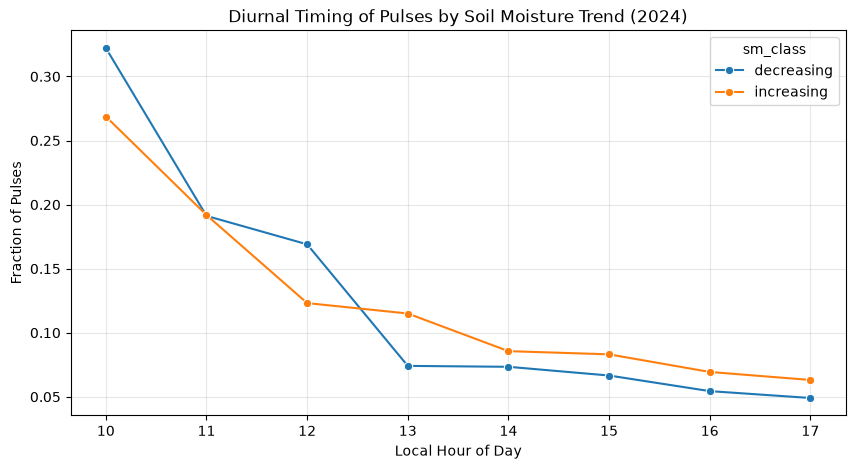

2025: decreasing 3,437, increasing 1,387


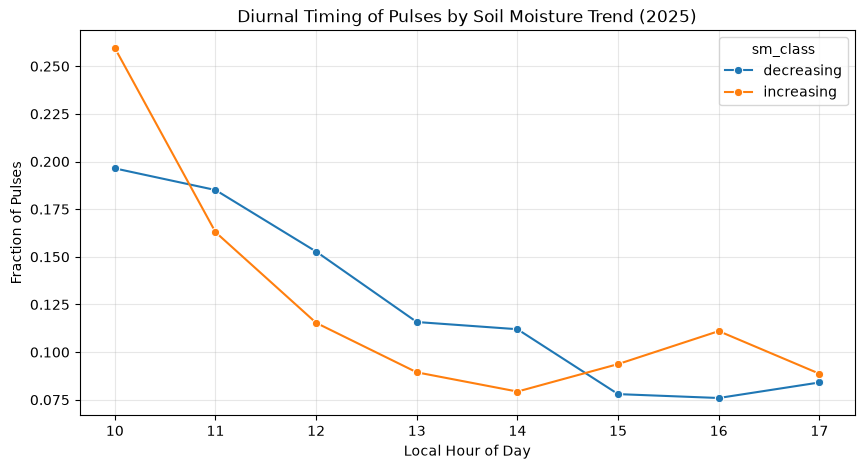

2024–2025: decreasing 6,230, increasing 2,987


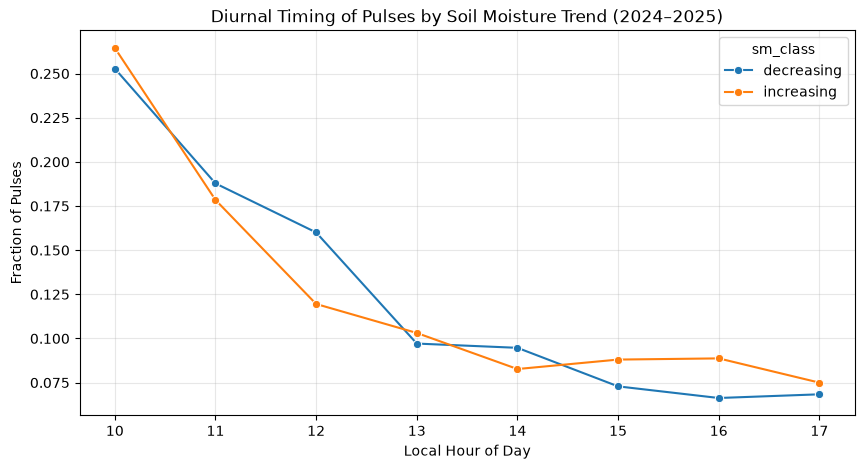

In [6]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns

YEARS = [2024, 2025]
HOUR_MIN, HOUR_MAX = 10, 17           
DIR = "/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/final_datasets"

def load(y):
    d = pd.read_parquet(f"{DIR}/lowCF_filtered_merged_with_incdec_MCD12Q1mask_{y}.parquet",
                        columns=["datetime_local", "pulse_start", "sm_class"])
    d = d[d["pulse_start"].astype(str).eq("True") & d["sm_class"].isin(["increasing", "decreasing"])].copy()
    d["hour"] = pd.to_datetime(d["datetime_local"]).dt.hour
    return d[d["hour"].between(HOUR_MIN, HOUR_MAX)].assign(year=y)

all_df = pd.concat([load(y) for y in YEARS], ignore_index=True)

for tag, plot_df in [(str(y), all_df[all_df["year"] == y]) for y in YEARS] + [(f"{YEARS[0]}–{YEARS[-1]}", all_df)]:
    #count pulses per hour per class
    counts = plot_df.groupby(["sm_class", "hour"]).size().reset_index(name="count")
    #normalize within each class
    counts["fraction"] = counts.groupby("sm_class")["count"].transform(lambda x: x / x.sum())
    print(f"{tag}: " + ", ".join(f"{k} {v:,}" for k, v in plot_df["sm_class"].value_counts().items()))

    plt.figure(figsize=(10, 5))
    sns.lineplot(data=counts, x="hour", y="fraction", hue="sm_class", marker="o")
    plt.xlabel("Local Hour of Day")
    plt.ylabel("Fraction of Pulses")
    plt.title(f"Diurnal Timing of Pulses by Soil Moisture Trend ({tag})")
    plt.xticks(range(HOUR_MIN, HOUR_MAX + 1))
    plt.grid(alpha=0.3)
    plt.savefig(f"Pulse_hour_by_class_{tag}.pdf", bbox_inches="tight")
    plt.show()